In [15]:
from create_datasets import create_new, get_classified_ids, clean_result
from paths import DatasetPaths, CT_NOVTT, VIDEOS_SAMPLE_1000
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             cohen_kappa_score, ConfusionMatrixDisplay)
from path import Path

In [2]:
ct_novtt_folder = "C:/Users/isabe/Documents/TESI/project/conspiracy-detection/classification_results/CT_NOVTT_video"
videos_sample_1000_folder = "C:/Users/isabe/Documents/TESI/project/conspiracy-detection/classification_results/videos_sample_1000"
balanced_sample_dir = "C:/Users/isabe/Documents/TESI/project/conspiracy-detection/classification_results/balanced_sample_2k"


In [3]:
create_new(ct_novtt_folder, videos_sample_1000_folder, balanced_sample_dir, 50)


In [4]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.inter_rater import aggregate_raters, fleiss_kappa

In [32]:
word = "classification_gemma_it"
word = Path(word)
word = str(word).split("classification_")[1]
word

'gemma_it'

In [35]:
dframes = []

for f in Path(balanced_sample_dir).iterdir():
    df = pd.read_csv(f)
    df["config"] = str(f.stem).split("classification_")[1]
    dframes.append(df)

results_concat = pd.concat(dframes, ignore_index = True)

grouped = results_concat.groupby("config")


In [87]:
for f in Path(balanced_sample_dir).iterdir():
    df = pd.read_csv(f)
    df["config"] = str(f.stem).split("classification_")[1]
    g = df.groupby("label")
    print(g.count())

       video_id  classification_gemma4_E4B  classification_qwen3VL_8BI  \
label                                                                    
0           781                        781                         781   
1           795                        795                         795   

       classification_qwen3VL_32BI  classification_gemma4_31BIT  config  
label                                                                    
0                              781                          781     781  
1                              795                          795     795  
       video_id  classification_gemma4_E4B  classification_qwen3VL_8BI  \
label                                                                    
0           781                        781                         781   
1           795                        795                         795   

       classification_qwen3VL_32BI  classification_gemma4_31BIT  config  
label                               

In [36]:
grouped.head(5)

,video_id,classification_gemma4_E4B,classification_qwen3VL_8BI,classification_qwen3VL_32BI,classification_gemma4_31BIT,label,config
0,6946325161821883654,0,0,0,0,0,it_concat_defintion_frames_shotbased
1,6962360054330707205,0,0,0,0,0,it_concat_defintion_frames_shotbased
2,6969058362986089734,0,0,0,0,0,it_concat_defintion_frames_shotbased
3,6971601931156376838,0,0,0,0,0,it_concat_defintion_frames_shotbased
4,6974021498235276550,0,0,0,0,0,it_concat_defintion_frames_shotbased
...,...,...,...,...,...,...,...
26792,6946325161821883654,0,0,0,0,0,v_simple
26793,6962360054330707205,0,0,0,0,0,v_simple
26794,6969058362986089734,0,0,0,0,0,v_simple
26795,6971601931156376838,0,0,0,0,0,v_simple


In [38]:
models = [c for c in df.columns if c not in ("video_id", "label", "config")]
classes = sorted(df["label"].unique())
rows = []
for cfg, g in grouped:
    for m in models:
        
        y, p = g["label"], g[m]
        m = m.split("classification_")[1]
        r = {"config": cfg, "model": m,
                "accuracy": accuracy_score(y, p),
                "kappa_vs_label": cohen_kappa_score(y, p, labels=classes)}
        
        pr, rc, f1, _ = precision_recall_fscore_support(
            y, p, labels=classes, average="weighted", zero_division=0)
        r.update({f"precision_weighted": pr, f"recall_weighted": rc, f"f1_weighted": f1})
        
        rows.append(r)
res = pd.DataFrame(rows)
res.to_csv("C:/Users/isabe/Documents/TESI/project/conspiracy-detection/metrics_summary.csv", index=False)


In [39]:
res.shape

(72, 7)

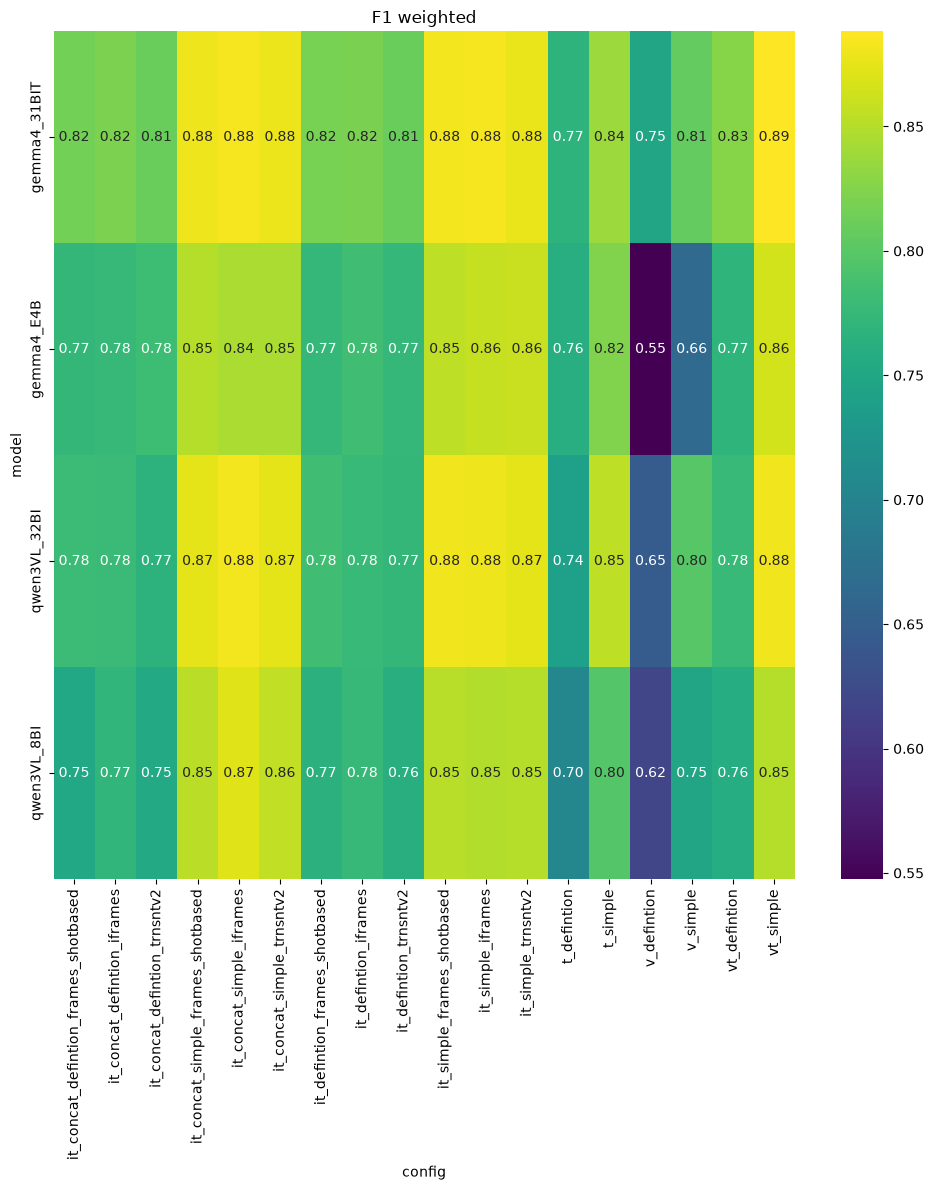

In [ ]:
plt.figure(figsize=(10, 12))
sns.heatmap(res.pivot(index="model", columns="config", values="f1_weighted"),
            annot=True, fmt=".2f", cmap="viridis")
plt.title("F1 weighted"); plt.tight_layout()
plt.savefig("C:/Users/isabe/Documents/TESI/project/conspiracy-detection/images/heatmap_f1.png", dpi=200)


In [ ]:
pr, rc, f1, _ = precision_recall_fscore_support(
    y, p, labels=classes, average="weighted", zero_division=0)
r = {"config": cfg, "model": m,
     "accuracy": accuracy_score(y, p),
     "precision_weighted": pr, "recall_weighted": rc, "f1_weighted": f1,
     "kappa_vs_label": cohen_kappa_score(y, p, labels=classes)}
rows.append(r)

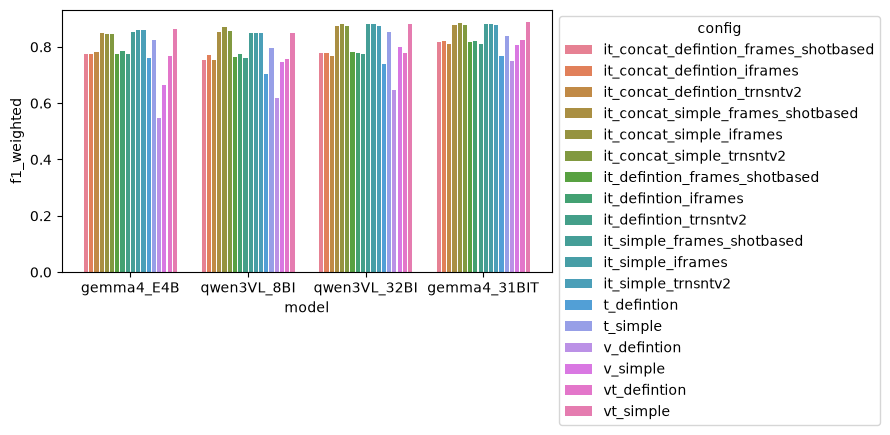

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=res, x="model", y="f1_weighted", hue="config", ax=ax, gap=0.2)
# barre d'errore: l'ordine delle barre in seaborn è per hue, poi per x
for bar, (_, r) in zip(ax.patches, res.sort_values(["config", "model"]).iterrows()):
    ax.errorbar(bar.get_x() + bar.get_width() / 2, r["f1_weighted"])
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig("C:/Users/isabe/Documents/TESI/project/conspiracy-detection/images/barplot_f1.png", dpi=200)

vt_simple


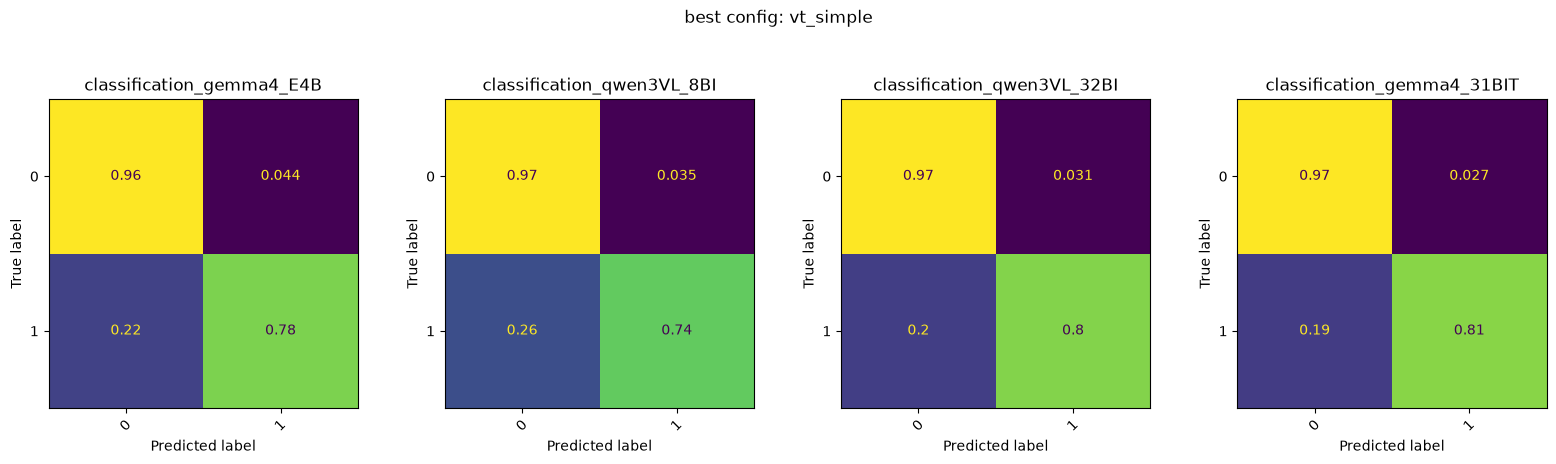

In [ ]:
best = res.groupby("config")["f1_weighted"].mean().idxmax()
print(best)
g = results_concat[results_concat["config"] == best]
fig, axs = plt.subplots(1, len(models), figsize=(4 * len(models), 4))
for ax, m in zip(np.atleast_1d(axs), models):
    ConfusionMatrixDisplay.from_predictions(
        g["label"], g[m], labels=classes, normalize="true",
        ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(m)
fig.suptitle(f"best config: {best}", y=1.1)
plt.tight_layout()
plt.savefig("C:/Users/isabe/Documents/TESI/project/conspiracy-detection/images/confusion_best_config.png", dpi=200)

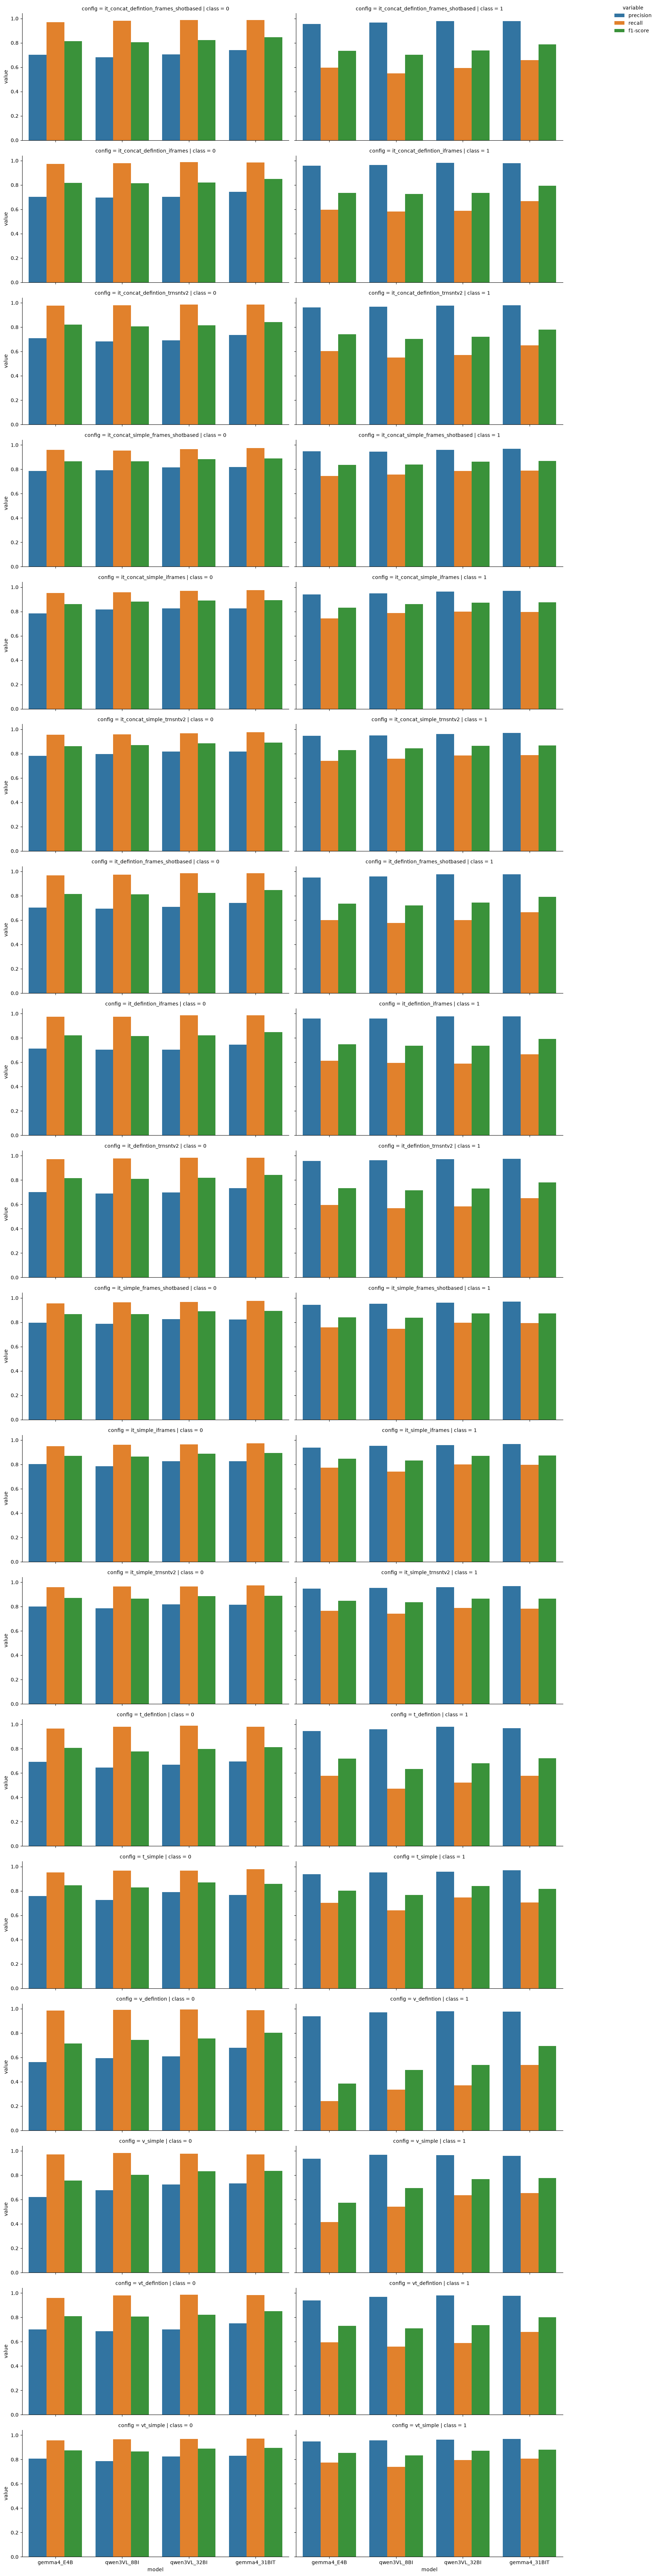

In [86]:
from sklearn.metrics import classification_report

rows = []
for cfg, g in grouped:
    for m in models:
        rep = classification_report(g["label"], g[m], labels=classes,
                                    output_dict=True, zero_division=0)
        m = m.split("classification_")[1]
        for c in classes:
            
            rows.append({"config": cfg, "model": m, "class": c, **rep[str(c)]})
per_class = pd.DataFrame(rows)

ax = sns.catplot(data=per_class.melt(id_vars=["config", "model", "class"],
                                value_vars=["precision", "recall", "f1-score"]),
            x="model", y="value", hue="variable", col="class",
            row="config", kind="bar", height=4, aspect=2)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))           
plt.savefig("C:/Users/isabe/Documents/TESI/project/conspiracy-detection/images/per_class_metrics.png", dpi=200)

In [93]:
from itertools import combinations

In [96]:
codes = {c: i for i, c in enumerate(classes)}

In [97]:
fleiss, kappa_mats = {}, {}
for cfg, g in grouped:
    K = pd.DataFrame(1.0, index=models, columns=models)
    for a, b in combinations(models, 2):
        K.loc[a, b] = K.loc[b, a] = cohen_kappa_score(g[a], g[b])
    kappa_mats[cfg] = K
    data = g[models].apply(lambda s: s.map(codes)).values
    table, _ = aggregate_raters(data, n_cat=len(codes))
    fleiss[cfg] = fleiss_kappa(table, method="fleiss")
    agree = np.mean([(g[a] == g[b]).mean() for a, b in combinations(models, 2)])
    print(f"{cfg}: Fleiss kappa={fleiss[cfg]:.3f}  accordo medio={agree:.3f}")

it_concat_defintion_frames_shotbased: Fleiss kappa=0.788  accordo medio=0.909
it_concat_defintion_iframes: Fleiss kappa=0.800  accordo medio=0.914
it_concat_defintion_trnsntv2: Fleiss kappa=0.791  accordo medio=0.911
it_concat_simple_frames_shotbased: Fleiss kappa=0.847  accordo medio=0.926
it_concat_simple_iframes: Fleiss kappa=0.849  accordo medio=0.927
it_concat_simple_trnsntv2: Fleiss kappa=0.858  accordo medio=0.931
it_defintion_frames_shotbased: Fleiss kappa=0.780  accordo medio=0.905
it_defintion_iframes: Fleiss kappa=0.791  accordo medio=0.909
it_defintion_trnsntv2: Fleiss kappa=0.790  accordo medio=0.910
it_simple_frames_shotbased: Fleiss kappa=0.854  accordo medio=0.929
it_simple_iframes: Fleiss kappa=0.854  accordo medio=0.929
it_simple_trnsntv2: Fleiss kappa=0.860  accordo medio=0.933
t_defintion: Fleiss kappa=0.754  accordo medio=0.900
t_simple: Fleiss kappa=0.829  accordo medio=0.920
v_defintion: Fleiss kappa=0.612  accordo medio=0.879
v_simple: Fleiss kappa=0.734  accord

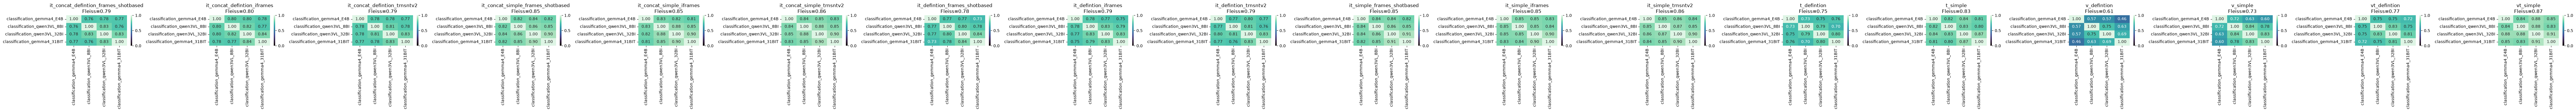

In [99]:
fig, axs = plt.subplots(1, len(kappa_mats), figsize=(5 * len(kappa_mats), 4))
for ax, (cfg, K) in zip(np.atleast_1d(axs), kappa_mats.items()):
    sns.heatmap(K, annot=True, fmt=".2f", vmin=0, vmax=1, cmap="mako", ax=ax)
    ax.set_title(f"{cfg}\nFleiss={fleiss[cfg]:.2f}")
plt.tight_layout()
plt.savefig("kappa_models.png", dpi=200)